# Keras
- The core data structures of Keras are **layers** and **models**.
- models:
  - sequential model (linear stack of layers)
  - functional API model
- from https://keras.io/guides/functional_api/

In [ ]:
import numpy as np
import tensorflow as tf
import keras
from keras import layers
from keras.models import Sequential, Model
from keras.layers import Dense, Input
from keras.utils import to_categorical

# Models and Layers
- Layer: inner computation block
- Model: define the outer model

## Layers in Keras
- A layer encapsulates both:
  - a state (the layer's "weights") and
  - a transformation from inputs to outputs (a "call", the layer's forward pass)
  

## Models and Layers examples
- Input() : used to instantiate a Keras tensor (Keras tensor: a symbolic tensor-like object, which we augment with certain attributes)
- Dense, Flatten, Conv2D, SimpleRNN, ...

In [ ]:
# 784-dimensional vector input (flattened)
inputs = Input(shape=(784,))   # 784-dimensional vector. The batch size is always omitted
                               # since only the shape of each sample is specified.
# image input
img_inputs = Input(shape=(28, 28, 1))

In [ ]:
inputs.shape, img_inputs.shape, inputs.dtype, img_inputs.dtype

((None, 784), (None, 28, 28, 1), 'float32', 'float32')

In [ ]:
# input
inputs = Input(shape=(784,))
x = layers.Dense(64, activation="relu")(inputs)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(10)(x)

In [ ]:
# create Model (should begin with Input() layer)
model = keras.Model(inputs=inputs, outputs=outputs, name="mnist_model")

In [ ]:
model.summary()

Model: "mnist_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

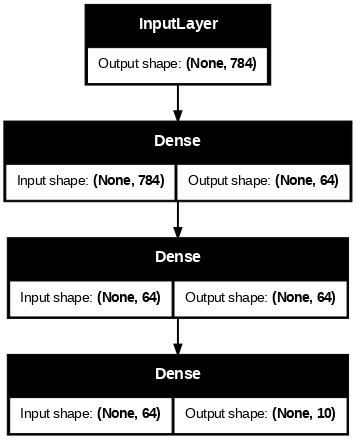

In [ ]:
keras.utils.plot_model(model, "my_first_model.png", show_shapes=True, dpi=70)

## using Sequential API

In [ ]:
# Sequential API
model = Sequential()
model.add(Input(shape=(784,)))
model.add(Dense(64, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(10))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

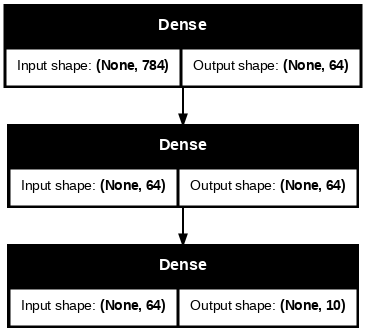

In [ ]:
# plot the model

keras.utils.plot_model(model, "my_first_model_with_shape_info.png", show_shapes=True, dpi=72)

## using Functional API

In [ ]:
inputs = Input(shape=(784,))
x = Dense(64, activation="relu")(inputs)
x = Dense(64, activation="relu")(x)
outputs = Dense(10, activation='softmax')(x)

model = Model(inputs=inputs, outputs=outputs, name="mnist_model")
model.summary()

Model: "mnist_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# no of parameters to train
# 784 * 64 + 64 = 50240
# 64 * 64 + 64 = 4160
# 64 * 10 + 10 = 650

# Training, evaluation, and Inference

---
- try to use Sequential() model, with MNIST dataset

In [ ]:
from tensorflow.keras.datasets.mnist import load_data
(x_train, y_train), (x_test, y_test) = load_data()
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (10000, 28, 28) (60000,) (10000,)


In [ ]:
x_train = x_train.reshape(60000, 784).astype("float32") / 255.
x_test = x_test.reshape(10000, 784).astype("float32") / 255.

In [ ]:
# one-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)
print(y_train.shape, y_test.shape)

(60000, 10) (10000, 10)


In [ ]:
y_train[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

In [ ]:
model.compile(
    loss=keras.losses.CategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)
history = model.fit(x_train, y_train, batch_size=100, epochs=5, validation_split=0.2)

test_scores = model.evaluate(x_test, y_test, verbose=2)
print("Test loss:", test_scores[0])
print("Test accuracy:", test_scores[1])

Epoch 1/5
480/480 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9787 - loss: 0.0717 - val_accuracy: 0.9688 - val_loss: 0.1076
Epoch 2/5
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9819 - loss: 0.0583 - val_accuracy: 0.9717 - val_loss: 0.0947
Epoch 3/5
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9848 - loss: 0.0516 - val_accuracy: 0.9725 - val_loss: 0.0969
Epoch 4/5
480/480 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9863 - loss: 0.0450 - val_accuracy: 0.9720 - val_loss: 0.0973
Epoch 5/5
480/480 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9877 - loss: 0.0382 - val_accuracy: 0.9722 - val_loss: 0.0997
313/313 - 1s - 4ms/step - accuracy: 0.9751 - loss: 0.0880
Test loss: 0.08795670419931412
Test accuracy: 0.9750999808311462


- we can see that size(train)=60000*0.8=48000 (480 steps/epoch)
- and size(val) = 60000*0.2=12000

In [ ]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

## Save the model
---

- There are two different types of saving models
  - Tensorflow SavedModel (recommended)
    - model architecture
    - model weight values (that were learned during training)
    - model training config, if any (as passed to compile)
    - optimizer and its state, if any (to restart training where you left off)
  - previous keras H5 (simplified version)
  - for more information: see https://www.tensorflow.org/guide/keras/save_and_serialize?hl=ko

In [ ]:
# method 1: savedmodel type (keras 포맷) - keras 표준 (권장)
# 모델 구조, 가중치, 옵티마이저 상태까지 모두 저장 - 단일 파일로 관리 편리

model.save("my_model.keras")
del model
# Recreate the exact same model purely from the file:
model = keras.models.load_model("my_model.keras")

In [ ]:
# method 2: hdf5 (.h5) type - Old type
model.save("my_model.h5")
del model
model = keras.models.load_model("my_model.h5")

# To define multiple models
- a single graph of layers can be used to generate multiple models

In [ ]:
encoder_input = Input(shape=(28, 28, 1))
x = layers.Conv2D(16, 3, activation="relu")(encoder_input)
x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(3)(x)
x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.Conv2D(16, 3, activation="relu")(x)
encoder_output = layers.GlobalMaxPooling2D()(x)
            # (batch_size, rows, columns, channels)->(batch_size, channels)

encoder = Model(encoder_input, encoder_output, name="encoder")
encoder.summary()

x = layers.Reshape((4, 4, 1))(encoder_output)
x = layers.Conv2DTranspose(16, 3, activation="relu")(x)
x = layers.Conv2DTranspose(32, 3, activation="relu")(x)
x = layers.UpSampling2D(3)(x)
x = layers.Conv2DTranspose(16, 3, activation="relu")(x)
decoder_output = layers.Conv2DTranspose(1, 3, activation="relu")(x)

autoencoder = Model(encoder_input, decoder_output, name="autoencoder")
autoencoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 6, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 16)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,672 (72.94 KB)

 Trainable params: 18,672 (72.94 KB)

 Non-trainable params: 0 (0.00 B)

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 6, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 16)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 6, 6, 16)       │           160 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 8, 8, 32)       │         4,640 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 26, 26, 16)     │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 1)      │           145 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,241 (110.32 KB)

 Trainable params: 28,241 (110.32 KB)

 Non-trainable params: 0 (0.00 B)

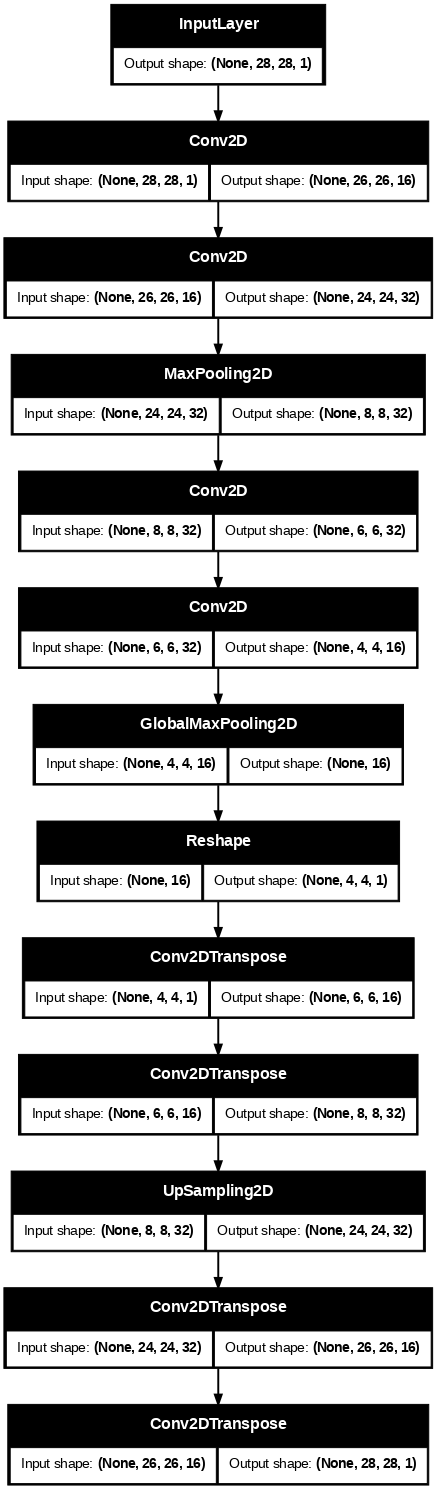

In [ ]:
keras.utils.plot_model(autoencoder, "my_autoencoder_info.png", show_shapes=True, dpi=70)

## All models are callable, just like layers
---

In [ ]:
encoder_input = Input(shape=(28, 28, 1), name="original_img")
x = layers.Conv2D(16, 3, activation="relu")(encoder_input)
x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(3)(x)
x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.Conv2D(16, 3, activation="relu")(x)
encoder_output = layers.GlobalMaxPooling2D()(x)  # pool size equals to the size of the input

encoder = keras.Model(encoder_input, encoder_output, name="encoder")
encoder.summary()

decoder_input = keras.Input(shape=(16,), name="encoded_img")
x = layers.Reshape((4, 4, 1))(decoder_input)
x = layers.Conv2DTranspose(16, 3, activation="relu")(x)
x = layers.Conv2DTranspose(32, 3, activation="relu")(x)
x = layers.UpSampling2D(3)(x)
x = layers.Conv2DTranspose(16, 3, activation="relu")(x)
decoder_output = layers.Conv2DTranspose(1, 3, activation="relu")(x)

decoder = keras.Model(decoder_input, decoder_output, name="decoder")
decoder.summary()

autoencoder_input = keras.Input(shape=(28, 28, 1), name="img")
encoded_img = encoder(autoencoder_input)              # model called
decoded_img = decoder(encoded_img)
autoencoder = keras.Model(autoencoder_input, decoded_img, name="autoencoder")
autoencoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ original_img (InputLayer)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 6, 6, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 4, 4, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d_1          │ (None, 16)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,672 (72.94 KB)

 Trainable params: 18,672 (72.94 KB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ img (InputLayer)                │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 16)             │        18,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 28, 28, 1)      │         9,569 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,241 (110.32 KB)

 Trainable params: 28,241 (110.32 KB)

 Non-trainable params: 0 (0.00 B)

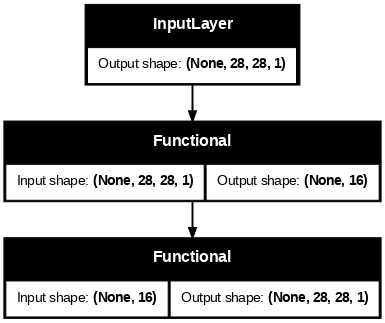

In [ ]:
keras.utils.plot_model(autoencoder, "my_second_autoencoder_info.png", show_shapes=True, dpi=70)

# Backend operation (Keras.ops)
- Keras 3부터는 특정 백엔드에 종속되었던 기존의 keras.backend (흔히 K로 임포트하던 방식) 대신, TensorFlow, PyTorch, JAX 등 어떤 백엔드 위에서도 동일하게 동작하는 프레임워크 독립적인 keras.ops를 표준으로 사용한다.
- keras.ops의 표준화: 과거에는 백엔드 종속적인 저수준 연산을 피하고자 tf.*를 직접 쓰라는 조언이 있었으나, Keras 3부터는 어떤 백엔드 위에서도 동일하게 동작하는 keras.ops가 그 역할을 완전히 대체했다.
- NumPy 및 TensorFlow API 표준 차용:
  - Keras가 멀티 백엔드로 확장되면서 만든 keras.ops 역시 개발자들에게 가장 익숙한 기존 TensorFlow/NumPy 함수의 시그니처와 이름을 그대로 계승함.
- 백엔드별 동적 바인딩 (Abstraction Layer):
  - 겉보기에는 tf.*나 기존 백엔드 함수와 완전히 똑같이 보이고 사용법도 일치하지만, 내부적으로는 현재 활성화된 백엔드(예: PyTorch나 JAX)에 맞추어 해당 프레임워크의 저수준 연산으로 자동 변환(dispatch)되어 실행된다.
  - 예컨대, 백엔드를 PyTorch로 설정하고 keras.ops.sum(x)를 호출하면, 내부적으로 PyTorch의 torch.sum이 호출된다.
- Keras 코드 안에서는: tf.math, tf.keras.backend 대신 keras.ops를 표준으로 사용 권장. (그래야 백엔드를 바꿀 때 코드를 고칠 필요가 없다.)

In [1]:
!echo $HOME

/root


In [2]:
!ls -a /root

.	 .cache   .ipython  .keras	   .npm      .tmux.conf
..	 .config  .julia    .launchpadlib  .profile  .wget-hsts
.bashrc  .gemini  .jupyter  .local	   .ssh


In [3]:
!more $HOME/.keras/keras.json   # backend (for low level functions) is tensorflow
                                # among Tensorflow, Theano, CNTK

{
    "floatx": "float32",
    "epsilon": 1e-07,
    "backend": "tensorflow",
    "image_data_format": "channels_last"
}


In [9]:
print(keras.config.backend())

tensorflow


### Some useful functions

In [47]:
# 1. 텐서 생성 및 변환 (Creation & Conversion)
import numpy as np
x = np.array([[1, 2, 3], [4, 5, 6]])

print(keras.ops.convert_to_tensor(x))
print("---\n")

print(keras.ops.zeros(x.shape), keras.ops.ones(x.shape))
print("---\n")

keras.ops.zeros_like(x), keras.ops.ones_like(x)

tf.Tensor(
[[1 2 3]
 [4 5 6]], shape=(2, 3), dtype=int64)
---

tf.Tensor(
[[0. 0. 0.]
 [0. 0. 0.]], shape=(2, 3), dtype=float32) tf.Tensor(
[[1. 1. 1.]
 [1. 1. 1.]], shape=(2, 3), dtype=float32)
---



(<tf.Tensor: shape=(2, 3), dtype=int64, numpy=
 array([[0, 0, 0],
        [0, 0, 0]])>,
 <tf.Tensor: shape=(2, 3), dtype=int64, numpy=
 array([[1, 1, 1],
        [1, 1, 1]])>)

In [48]:
# 2. 형상 및 차원 조작 (Shape & Dimension Manipulation)
x1 = np.array([[1,2,3], [4,5,6]])

print(keras.ops.reshape(x1, newshape=(3,2)))
print("---\n")
print(keras.ops.transpose(x1, axes=None))
print("---\n")
print(keras.ops.expand_dims(x1, -1))  # 지정한 축에 크기가 1인 차원을 추가
print("---\n")

x2 = np.array([[[7,8,9], [1,2,3]]])
print(x2.shape)
print("---\n")

print(keras.ops.squeeze(x2, axis=None)) # 크기가 1인 차원을 제거하여 차원 수를 줄인다.
print("---\n")

keras.ops.concatenate([x1, x1], axis=0) # tensors 대신 실제 합칠 텐서 리스트 전달

tf.Tensor(
[[1 2]
 [3 4]
 [5 6]], shape=(3, 2), dtype=int64)
---

tf.Tensor(
[[1 4]
 [2 5]
 [3 6]], shape=(3, 2), dtype=int64)
---

tf.Tensor(
[[[1]
  [2]
  [3]]

 [[4]
  [5]
  [6]]], shape=(2, 3, 1), dtype=int64)
---

(1, 2, 3)
---

tf.Tensor(
[[7 8 9]
 [1 2 3]], shape=(2, 3), dtype=int64)
---



<tf.Tensor: shape=(4, 3), dtype=int64, numpy=
array([[1, 2, 3],
       [4, 5, 6],
       [1, 2, 3],
       [4, 5, 6]])>

In [49]:
# 3. 산술 및 수학 연산 (Math Operations)
print(keras.ops.maximum(x1, x2), keras.ops.minimum(x1, x2))
print("---\n")

print(keras.ops.clip(x1, 1, 3))  # min_value, max_value
print("---\n")

print(keras.ops.exp(x1), keras.ops.log(x1))
print("---\n")

keras.ops.square(x1), keras.ops.sqrt(x1)

tf.Tensor(
[[[7 8 9]
  [4 5 6]]], shape=(1, 2, 3), dtype=int64) tf.Tensor(
[[[1 2 3]
  [1 2 3]]], shape=(1, 2, 3), dtype=int64)
---

tf.Tensor(
[[1 2 3]
 [3 3 3]], shape=(2, 3), dtype=int64)
---

tf.Tensor(
[[  2.7182817   7.389056   20.085537 ]
 [ 54.59815   148.41316   403.4288   ]], shape=(2, 3), dtype=float32) tf.Tensor(
[[0.        0.6931472 1.0986123]
 [1.3862944 1.609438  1.7917595]], shape=(2, 3), dtype=float32)
---



(<tf.Tensor: shape=(2, 3), dtype=int64, numpy=
 array([[ 1,  4,  9],
        [16, 25, 36]])>,
 <tf.Tensor: shape=(2, 3), dtype=float32, numpy=
 array([[1.       , 1.4142135, 1.7320508],
        [2.       , 2.2360678, 2.4494896]], dtype=float32)>)

In [62]:
# 4. 축소 연산 (Reduction Operations)

print(keras.ops.sum(x, axis=None, keepdims=False))
print("---\n")

print(keras.ops.mean(x, axis=None, keepdims=True),"\n",
      keras.ops.mean(x, axis=None, keepdims=False))
print("---\n")

print(keras.ops.max(x, axis=None), keras.ops.min(x, axis=None))
print("---\n")

keras.ops.argmax(x, axis=None), keras.ops.argmin(x, axis=None)


tf.Tensor(21, shape=(), dtype=int64)
---

tf.Tensor([[3.5]], shape=(1, 1), dtype=float32) 
 tf.Tensor(3.5, shape=(), dtype=float32)
---

tf.Tensor(6, shape=(), dtype=int64) tf.Tensor(1, shape=(), dtype=int64)
---



(<tf.Tensor: shape=(), dtype=int32, numpy=5>,
 <tf.Tensor: shape=(), dtype=int32, numpy=0>)

In [76]:
# 5. 선형대수 및 신경망 연산 (Linear Algebra & Neural Network)

# 활성화 함수(sigmoid 등)를 사용하기 위해 x를 실수형(float32) 텐서로 변환.
x = keras.ops.convert_to_tensor(x, dtype="float32")
y = x  # 텐서는 불변 객체이므로 단순히 대입(y = x)하여 사용 가능.
print(y)
print("---\n")

print(keras.ops.matmul(x, keras.ops.transpose(y)))
print("---\n")

print(keras.ops.softmax(x, axis=-1))
print("---\n")

keras.ops.relu(x), keras.ops.sigmoid(x)

tf.Tensor(
[[1. 2. 3.]
 [4. 5. 6.]], shape=(2, 3), dtype=float32)
---

tf.Tensor(
[[14. 32.]
 [32. 77.]], shape=(2, 2), dtype=float32)
---

tf.Tensor(
[[0.09003057 0.24472848 0.6652409 ]
 [0.09003057 0.24472848 0.6652409 ]], shape=(2, 3), dtype=float32)
---



(<tf.Tensor: shape=(2, 3), dtype=float32, numpy=
 array([[1., 2., 3.],
        [4., 5., 6.]], dtype=float32)>,
 <tf.Tensor: shape=(2, 3), dtype=float32, numpy=
 array([[0.73105854, 0.880797  , 0.95257413],
        [0.98201376, 0.9933072 , 0.9975274 ]], dtype=float32)>)

# 예제: 새로운 Layer 생성 using Keras
- keras.layers.Layer
  - the class from which all layers inherit
  - It involves *computation*, defined in the `call()` method, and a weights.
- The weights can be defined in two ways:
  - by using add_weight()
  - by overriding build() : more flexible
- 백엔드가 TensorFlow, PyTorch, JAX 중 무엇이든 동일하게 동작한다.

In [82]:
## Example: the method `add_weight()` offers a shortcut to create weights

import keras

class SimpleDense(keras.layers.Layer):

    def __init__(self, units=32, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        # 입력 형태(input_shape)의 마지막 차원(feature 수)을 자동으로 가져온다
        input_dim = input_shape[-1]

        # 가중치 생성
        self.w = self.add_weight(
            shape=(input_dim, self.units),
            initializer="random_normal",
            trainable=True,
        )
        self.b = self.add_weight(
            shape=(self.units,), initializer="zeros", trainable=True
        )

    def call(self, inputs):
        return keras.ops.matmul(inputs, self.w) + self.b

# --- 사용 예시 ---
x = keras.ops.ones((2, 2))

# input_dim을 직접 넘길 필요 없이 출력 유닛 수만 지정한다
linear_layer = SimpleDense(units=4)
y = linear_layer(x)

print("출력 결과:\n", y)

출력 결과:
 tf.Tensor(
[[0.04517949 0.02719043 0.01280956 0.0865477 ]
 [0.04517949 0.02719043 0.01280956 0.0865477 ]], shape=(2, 4), dtype=float32)


In [84]:
# Note that the weights w and b are automatically tracked by the layer upon being set as layer attributes:
assert linear_layer.weights == [linear_layer.w, linear_layer.b]

In [85]:
linear_layer.weights

[<Variable path=simple_dense_2/variable_8, shape=(2, 4), dtype=float32, value=[[ 0.05724037  0.03590513  0.03850726  0.09352499]
  [-0.01206088 -0.0087147  -0.0256977  -0.00697729]]>,
 <Variable path=simple_dense_2/variable_9, shape=(4,), dtype=float32, value=[0. 0. 0. 0.]>]

# Exercise

- one-hot encoding:
  - one_hot() in keras: word hashing (not a real one-hot encoding function)
  - to_categorical() in keras: one-hot encoding
  - one_hot() in tf : one-hot encoding

- tf.one_hot and keras.utils.to_categorical
  - basically the same except that you give depth n in tf.one_hot()
  - returns array and tensor

In [96]:
y = [1, 2, 3, 2, 1]
tf.keras.utils.to_categorical(y)

array([[0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [0., 0., 0., 1.],
       [0., 0., 1., 0.],
       [0., 1., 0., 0.]])

In [101]:
print(tf.one_hot(y, 2))
print(tf.one_hot(y, 4))
print(tf.one_hot(y, 6))

tf.Tensor(
[[[1. 0.]
  [1. 0.]
  [1. 0.]
  [1. 0.]
  [1. 0.]
  [1. 0.]]], shape=(1, 6, 2), dtype=float32)
tf.Tensor(
[[[1. 0. 0. 0.]
  [1. 0. 0. 0.]
  [1. 0. 0. 0.]
  [1. 0. 0. 0.]
  [1. 0. 0. 0.]
  [1. 0. 0. 0.]]], shape=(1, 6, 4), dtype=float32)
tf.Tensor(
[[[1. 0. 0. 0. 0. 0.]
  [1. 0. 0. 0. 0. 0.]
  [1. 0. 0. 0. 0. 0.]
  [1. 0. 0. 0. 0. 0.]
  [1. 0. 0. 0. 0. 0.]
  [1. 0. 0. 0. 0. 0.]]], shape=(1, 6, 6), dtype=float32)
